# Du son au genre musical : ce qu’apporte un Vision Transformer

**Parcours du projet · V1 vérifiée · 30 octobre 2026 ; complément utilisateur vérifié le 7 novembre**

Nous cherchons à classer un morceau parmi huit genres, en comparant des indices
de timbre, rythme et harmonie avec des représentations issues d’un ViT préentraîné.
Le résultat est une expérience comparative, pas un système qui comprend toute la musique.

**Lecture :** les sorties sont sauvegardées. **Exécution :** choisir le noyau
« Music genres — V1 », puis redémarrer et tout exécuter. Ce parcours lit les
rapports vérifiés et trace des figures : aucun téléchargement, entraînement,
décodage test ou nouveau bootstrap. Les calculs audio sont dans
[02_analyse_audio](02_analyse_audio.ipynb).

Parcours : 1. Problème · 2. Littérature · 3. Données · 4–5. Signal et représentations
· 6. Modèles · 7. Mesure · 8. Expériences · 9. Erreurs · 10. Test · 11. Reproduction.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, platform
from importlib.metadata import version
start = Path(os.environ.get("MUSIC_GENRE_ROOT", Path.cwd())).resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "src/music_genre").is_dir() and (p / "reports/latest_final_test_report.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Ouvrir depuis le projet ou définir MUSIC_GENRE_ROOT.")
sys.path.insert(0, str(ROOT / "src"))
from music_genre.presentation.notebook_data import read_verified_json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
FIGURES = ROOT / "reports/notebooks-v1/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
def finish(fig, name):
    fig.savefig(FIGURES / (name + ".png"), dpi=160, bbox_inches="tight")
    fig.savefig(FIGURES / (name + ".svg"), bbox_inches="tight")
    plt.show()
    plt.close(fig)
print("Interpréteur :", sys.executable)
print("Python :", platform.python_version(), "| Racine :", ROOT)

Interpréteur : e:\projet\vision transformer\.venv\Scripts\python.exe
Python : 3.13.16 | Racine : E:\projet\vision transformer


In [2]:
pointer = read_verified_json(ROOT, "reports/latest_final_test_report.json", "00b96175ff338eecbc5cedee14e2d1022cb5fd13e9e56ebfccffd3fc1f071851")
test = read_verified_json(ROOT, pointer["report"]["path"], pointer["report"]["sha256"])
check = read_verified_json(ROOT, pointer["independent_statistics"]["path"], pointer["independent_statistics"]["sha256"])
assert check["status"] == "passed" and check["report_sha256"] == pointer["report"]["sha256"]
lock = read_verified_json(ROOT, test["lock"]["report"], test["lock"]["report_sha256"])
validation = read_verified_json(ROOT, "reports/final-validation-report-v1/report.json", "fca9a2a76d110001820816fa1c296aa1ecf49c6ae7a1b582bc7eef520d18a92a")
robustness = read_verified_json(ROOT, "reports/ROBUSTNESS_PANEL.json", "0bc34a83b2aa0d46d4f66b6c4bffe97261df5a7fc91f63543b54d29b3c3c4016")
for path, digest in test["source_and_input_sha256"].items():
    assert hashlib.sha256((ROOT / path).read_bytes()).hexdigest() == digest, path
manifest_path = lock["dataset"]["manifest"]
assert hashlib.sha256((ROOT / manifest_path).read_bytes()).hexdigest() == lock["artifacts"][manifest_path]
manifest = pd.read_csv(ROOT / manifest_path, dtype={"track_id": str, "artist_id": str})
labels = test["labels"]
assert manifest.groupby("split").size().to_dict() == lock["dataset"]["counts"]
print("Rapports et manifeste conformes ; contrôle indépendant :", check["status"])
print("Ce contrôle léger ne relit pas les 7 985 artefacts de la campagne.")

Rapports et manifeste conformes ; contrôle indépendant : passed
Ce contrôle léger ne relit pas les 7 985 artefacts de la campagne.


In [3]:
candidate = "vit_block6_hpss"
point = test["estimates"][candidate]
display(Markdown(f"**Test : macro-F1 {point['macro_f1']['point']:.4f} ; accuracy "
                 f"{100*point['accuracy']['point']:.2f} %**, sur {test['tracks']} morceaux "
                 f"et {test['artists']} artistes. Le candidat était choisi avant le test."))

**Test : macro-F1 0.5035 ; accuracy 51.16 %**, sur 778 morceaux et 202 artistes. Le candidat était choisi avant le test.

## 1. Quel problème avons-nous réellement résolu ?

Une classification supervisée à un seul label par morceau. FMA-small fournit
Electronic, Experimental, Folk, Hip-Hop, Instrumental, International, Pop et Rock.
Un morceau peut pourtant mélanger des styles ; sa catégorie d’archive n’est pas
une vérité musicale exhaustive. Gospel n’est pas couvert, Hip-Hop ne démontre
pas une couverture de toutes les formes de rap, aucun détecteur « inconnu » n’existe.

Question initiale : **la fusion de descripteurs musicaux avec le ViT améliore-t-elle
la classification ?** L’étude de la profondeur et des canaux HPSS est une autre
question, ajoutée au fil des résultats. Nous conservons aussi les résultats négatifs.

## 2. De la littérature aux décisions

| Travail | Idée retenue | Décision locale | Limite |
|---|---|---|---|
| [Tzanetakis & Cook, 2002](https://www.cs.cmu.edu/~gtzan/work/pubs/tsap02gtzan.pdf) | Timbre, rythme et hauteurs | Référence de descripteurs puis fusion | Pas de règle universelle des genres |
| [Sturm, 2013](https://link.springer.com/article/10.1007/s10844-013-0250-y) | L’accuracy ne décrit pas tout | Erreurs et perturbations | Pas de compréhension musicale déduite d’un score |
| [FMA, 2017](https://arxiv.org/abs/1612.01840) | Audio, métadonnées et partitions | Audit et contrôle des artistes | Collection et taxonomie limitées |
| [ViT, 2021](https://arxiv.org/abs/2010.11929) | Patches et transfert | ViT image gelé | Transfert image → audio à mesurer |
| [MAEST, 2023](https://arxiv.org/html/2309.16418v1) | Transfert depuis différents blocs | Comparaison blocs 6/12 | Notre ViT n’est pas MAEST |
| [FitzGerald, 2010](https://dafx.de/paper-archive/2010/DAFx10/DerryFitzGerald_DAFx10_P15.pdf) | Séparation par filtrage médian | Canaux original/harmonique/percussif | HPSS ne sépare pas voix et instruments |

Synthèse de la [revue locale sourcée](../docs/REVUE_BIBLIOGRAPHIQUE.md), dont les niveaux
de lecture sont précisés. AST, MERT, MusicFM et MuQ sont des pistes bibliographiques,
pas des modèles évalués ici. Aucun classement d’état de l’art n’est revendiqué.

## 3. Peut-on faire confiance à la comparaison ?

Les morceaux exclus ou en quarantaine restent traçables. Le manifeste retenu
contient 7 857 morceaux ; 126 sont en quarantaine et 17 exclus dans la revue
initiale. Les partitions sont fixées avant les expériences : les fenêtres d’un
même morceau ne sont pas réparties entre apprentissage et évaluation.

split,train,validation,test
genre,,,
Electronic,792,99,95
Experimental,794,100,97
Folk,786,99,100
Hip-Hop,772,100,98
Instrumental,786,93,96
International,794,98,100
Pop,782,94,92
Rock,793,97,100


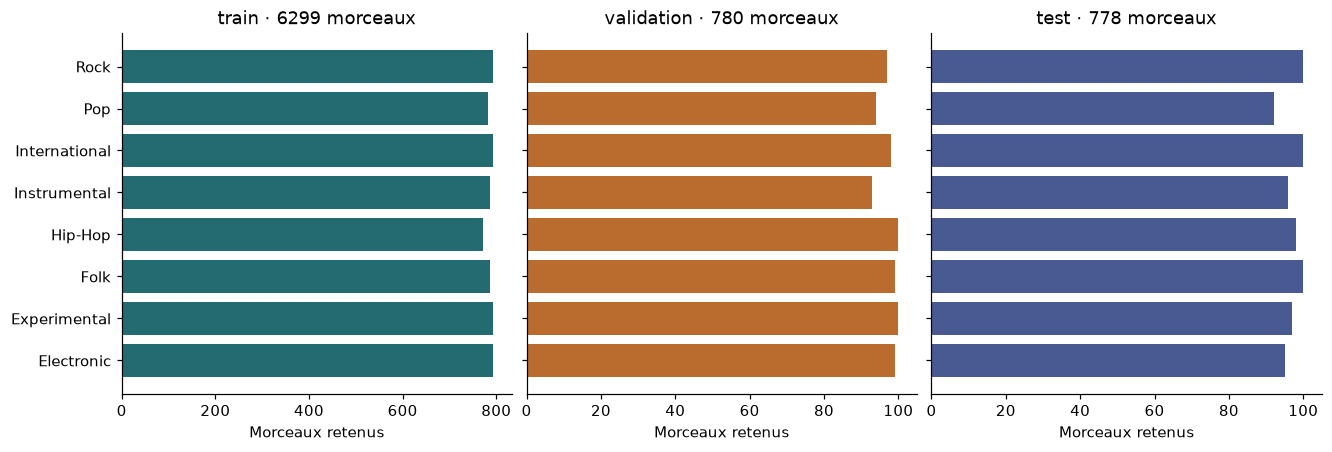

Aucun artiste partagé entre partitions du manifeste retenu.


In [4]:
distribution = pd.crosstab(manifest["genre"], manifest["split"]).reindex(labels)[["train", "validation", "test"]]
display(distribution)
artists = {split: set(manifest.loc[manifest.split == split, "artist_id"]) for split in distribution.columns}
assert not artists["train"] & artists["validation"]
assert not artists["train"] & artists["test"]
assert not artists["validation"] & artists["test"]
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, layout="constrained")
for ax, split, color in zip(axes, distribution.columns, ["#236b70", "#ba6b2e", "#485a91"]):
    ax.barh(labels, distribution[split], color=color)
    ax.set(title=f"{split} · {distribution[split].sum()} morceaux", xlabel="Morceaux retenus")
finish(fig, "01_partitions")
print("Aucun artiste partagé entre partitions du manifeste retenu.")

Les graphiques décrivent le corpus utilisé, pas la fréquence des genres dans le monde.
Séparer les artistes réduit un raccourci possible ; cela ne garantit pas l’absence
de tout biais. [Audit et décisions](../reports/REVUE_DONNEES.md).

## 4–5. Du signal aux informations musicales

L’analyse détaillée du **même passage train**, avec figures réellement calculées,
se trouve dans [02_analyse_audio](02_analyse_audio.ipynb). Elle montre signal,
fenêtres, STFT, log-Mel, MFCC, chroma, attaques, HPSS et tenseur du ViT.

| Représentation | Indices accessibles | Information perdue ou ambiguë |
|---|---|---|
| Mono 16 kHz | Évolution de l’amplitude | Spatialisation et fréquences au-delà de 8 kHz |
| STFT / log-Mel | Répartition temps–fréquence, énergie compressée | Compromis résolution ; phase absente des puissances |
| MFCC / statistiques spectrales | Enveloppe et texture | Instruments non identifiés ; ordre temporel réduit |
| Chroma | Énergie des 12 classes de hauteurs | Octaves agrégées ; accords non déterminés |
| Attaques / autocorrélation | Périodicités possibles | Ambiguïtés de tempo et demi/double tempo |
| HPSS | Continuités et transitoires | Fuites entre composantes ; pas des sources isolées |

Le spectrogramme n’est donc pas une conversion neutre en image. Ses paramètres,
son bornage et son redimensionnement déterminent les indices disponibles.

## 6. Comment les modèles prédisent-ils ?

```text
Audio → mono 16 kHz → fenêtres → représentation
  Descripteurs : timbre + rythme + harmonie → scaler train → régression logistique
  ViT gelé    : log-Mel → 224×224 → patches → tokens moyens → scaler → régression
  Fusion      : concaténation descripteurs + ViT bloc 12 → scaler → régression
  CNN         : log-Mel natif → réseau appris depuis zéro
Fenêtres → moyenne des probabilités → décision par morceau
```

Le candidat utilise original/H/P et les six premiers blocs d’un ViT-Tiny
préentraîné sur images. Ses 192 caractéristiques sont extraites **sans entraîner
les poids du ViT**. Le classificateur linéaire apprend sur train. Les CNN sont
appris depuis zéro : CNN contre ViT n’isole donc pas le seul effet de l’architecture.

## 7. Comment apprendre et mesurer sans choisir sur test ?

Les normalisations sont ajustées sur train. Validation sélectionne C et les
checkpoints CNN ; le test évalue les exports verrouillés, sans nouvel ajustement.
La macro-F1 est la moyenne des F1 des huit classes, donnant le même poids à chacune.
L’accuracy est la fraction totale de morceaux correctement classés.

Trois graines CNN mesurent une dispersion d’apprentissage. Leur moyenne de métriques
n’est pas un ensemble. Le bootstrap apparié rééchantillonne des **artistes entiers**
pour conserver le regroupement des morceaux. Les 2 000 tirages et leurs paramètres
étaient fixés avant test ; ils ne couvrent pas l’incertitude de tout le processus
de sélection et d’apprentissage.

## 8. Quelles expériences ont changé nos choix ?

Le tableau lit les rapports de validation. Il ne constitue pas une nouvelle
sélection. Les variantes et décisions adaptatives sont datées dans le
[registre](../docs/DECISIONS_EXPERIMENTALES.md).

,Système,Macro-F1 validation,Accuracy validation
0,Descripteurs,0.4612,0.4756
1,ViT bloc 12,0.5447,0.5538
2,Fusion,0.5219,0.5295
3,ViT bloc 6,0.5780,0.5885
4,Bloc 12 HPSS,0.5844,0.5974
5,Bloc 6 HPSS,0.5975,0.6128
6,CNN : moyenne 3 graines,0.5407,0.5560


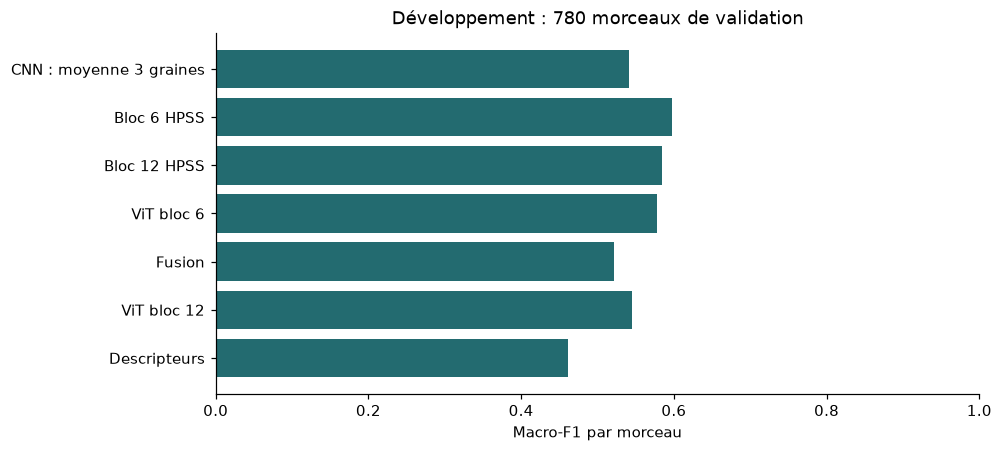

In [5]:
names = {"descriptor": "Descripteurs", "vit": "ViT bloc 12", "fusion": "Fusion",
         "vit_block6": "ViT bloc 6", "vit_hpss": "Bloc 12 HPSS",
         "vit_block6_hpss": "Bloc 6 HPSS", "cnn20_mean": "CNN : moyenne 3 graines"}
development = pd.DataFrame([
    {"Système": name, "Macro-F1 validation": validation["estimates"][key]["macro_f1"]["point"],
     "Accuracy validation": validation["estimates"][key]["accuracy"]["point"]}
    for key, name in names.items()])
display(development.round(4))
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.barh(development["Système"], development["Macro-F1 validation"], color="#236b70")
ax.set(xlim=(0, 1), xlabel="Macro-F1 par morceau", title="Développement : 780 morceaux de validation")
finish(fig, "02_validation")

La fusion bloc 12 + descripteurs régresse sur validation : l’hypothèse initiale
n’est pas confirmée dans cette recette. Bloc 6 + HPSS devient le candidat retenu,
sans démontrer une meilleure compréhension musicale ni un gain pour chaque genre.
L’ablation une/trois fenêtres change aussi le nombre d’exemples train.

Les CNN prolongés avaient un plafond de 20 époques, mais se sont arrêtés à 18/13/11
avec patience 3 ; checkpoints retenus 15/10/8. Augmenter seulement le plafond ne
force pas l’apprentissage à continuer. [Courbes et extension](../reports/EXTENSION_CNN.md).

## 9. Où le modèle échoue-t-il ?

Avant le test, un panel fixe de 64 morceaux validation a servi à étudier la
sensibilité au volume et au bruit. Ces scores ne sont pas ceux des 780 morceaux.

,Condition,Macro-F1,Classes changées / 64
0,identity,0.5479,0
1,gain_minus_6_db,0.5050,6
2,white_noise_snr_20_db,0.3648,26


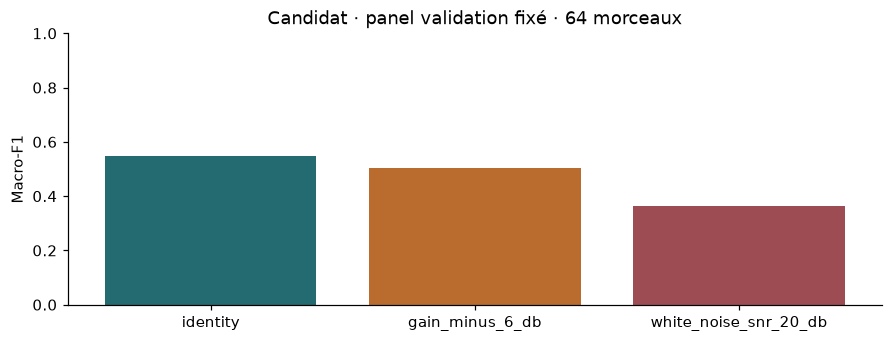

In [6]:
robust = pd.DataFrame([{"Condition": name, "Macro-F1": item["metrics"]["macro_f1"],
                       "Classes changées / 64": item["flipped_tracks"]}
                      for name, item in robustness["summary"].items()])
display(robust.round(4))
fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
ax.bar(robust["Condition"], robust["Macro-F1"], color=["#236b70", "#ba6b2e", "#9e4c54"])
ax.set(ylim=(0, 1), ylabel="Macro-F1", title="Candidat · panel validation fixé · 64 morceaux")
finish(fig, "03_robustesse")

Le candidat perd fortement sous bruit. Le bloc 6 original perd moins de F1 mais
change davantage de classes : aucun gagnant global en robustesse n’est établi.
Les 19 fiches d’écoute préparées n’ont pas d’annotations subjectives validées.
Nous ne décrivons donc pas des instruments ou paroles supposément entendus.

## 10. Que reste-t-il sur le test tenu à l’écart ?

L’évaluation est terminée : neuf exports, une référence majoritaire déterminée
sur train, 778 morceaux et 202 artistes. Les sorties et les 2 000 tirages ont été
contrôlés indépendamment. Le JSON brut conserve son état de création ; la preuve
externe ultérieure confirme `passed` et l’empreinte exacte du rapport.

,Système,Macro-F1,IC bas,IC haut,Accuracy
0,descriptor,0.3892,0.3011,0.4260,0.3959
1,vit,0.4641,0.3761,0.5073,0.4756
2,fusion,0.4791,0.3892,0.5142,0.4871
3,vit_block6,0.4883,0.3991,0.5294,0.4949
4,vit_hpss,0.4694,0.3844,0.5108,0.4794
5,vit_block6_hpss,0.5035,0.4133,0.5449,0.5116
6,cnn20_seed42,0.4539,0.3643,0.5003,0.4602
7,cnn20_seed43,0.4424,0.3536,0.4976,0.4640
8,cnn20_seed44,0.3995,0.3069,0.4502,0.4165
9,majority,0.0277,0.0157,0.0437,0.1247


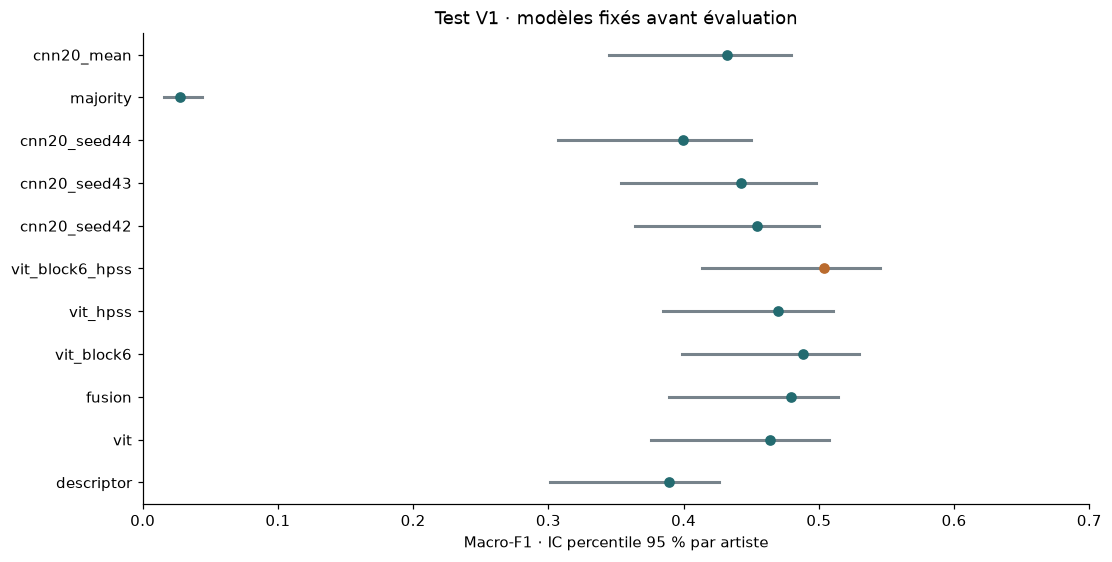

,Comparaison,point,low,high
0,vit_block6_hpss - vit,0.0394,0.0054,0.0715
1,fusion - vit,0.0150,-0.0277,0.0508
2,vit_block6_hpss - vit_hpss,0.0341,-0.0006,0.0658
3,vit_block6_hpss - vit_block6,0.0152,-0.0112,0.0406


In [7]:
scores = pd.DataFrame([{"Système": model,
    "Macro-F1": test["estimates"][model]["macro_f1"]["point"],
    "IC bas": test["estimates"][model]["macro_f1"]["low"],
    "IC haut": test["estimates"][model]["macro_f1"]["high"],
    "Accuracy": test["estimates"][model]["accuracy"]["point"]} for model in test["models"]])
display(scores.round(4))
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
for i, row in scores.iterrows():
    ax.plot([row["IC bas"], row["IC haut"]], [i, i], color="#77838b", lw=2)
    ax.scatter(row["Macro-F1"], i, color="#ba6b2e" if row["Système"] == candidate else "#236b70", zorder=3)
ax.set(yticks=range(len(scores)), yticklabels=scores["Système"], xlim=(0, 0.7),
       xlabel="Macro-F1 · IC percentile 95 % par artiste", title="Test V1 · modèles fixés avant évaluation")
finish(fig, "04_test_intervalles")
comparisons = pd.DataFrame([{"Comparaison": name, **values["macro_f1"]}
                            for name, values in test["differences"].items()])
display(comparisons.round(4))

La comparaison principale candidat − ViT original soutient un gain de macro-F1
dans ce protocole. Les trois intervalles secondaires incluent zéro ; le petit
gain ponctuel de fusion sur test n’établit pas sa supériorité. Même le gain
principal d’accuracy reste incertain. Les intervalles sont ponctuels, sans
correction des comparaisons multiples ; comparer les **différences appariées**.

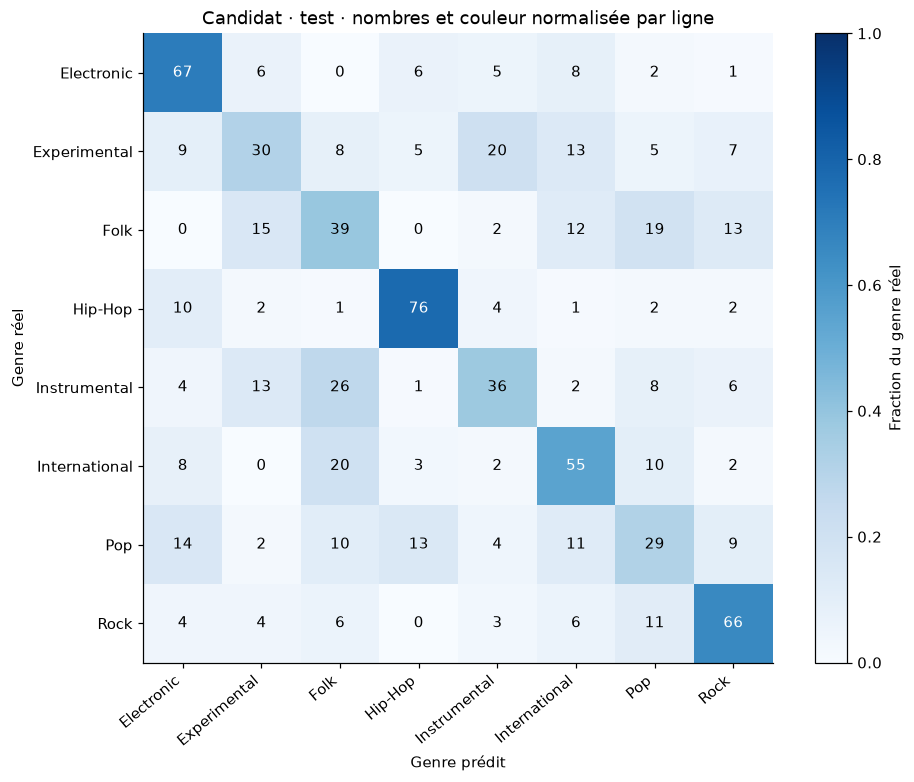

,precision,recall,f1-score,support
Electronic,0.5776,0.7053,0.6351,95.0
Experimental,0.4167,0.3093,0.3550,97.0
Folk,0.3545,0.3900,0.3714,100.0
Hip-Hop,0.7308,0.7755,0.7525,98.0
Instrumental,0.4737,0.3750,0.4186,96.0
International,0.5093,0.5500,0.5288,100.0
Pop,0.3372,0.3152,0.3258,92.0
Rock,0.6226,0.6600,0.6408,100.0


Baisse validation → test : 9.40 points de macro-F1.


,sum_call_seconds,median_call_seconds,p95_call_seconds
descriptor,131.969,0.169,0.180
vit,221.132,0.278,0.303
fusion,300.547,0.384,0.403
vit_block6,159.977,0.204,0.214
vit_hpss,913.420,1.173,1.198
vit_block6_hpss,848.838,1.092,1.115
cnn20_seed42,95.373,0.123,0.129
cnn20_seed43,96.459,0.124,0.129
cnn20_seed44,95.488,0.122,0.131


In [8]:
cm = np.asarray(test["classification"][candidate]["confusion_matrix"])
fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
im = ax.imshow(cm / cm.sum(axis=1, keepdims=True), vmin=0, vmax=1, cmap="Blues")
for i in range(8):
    for j in range(8):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i,j]/cm[i].sum() > .5 else "black")
ax.set(xticks=range(8), xticklabels=labels, yticks=range(8), yticklabels=labels,
       xlabel="Genre prédit", ylabel="Genre réel", title="Candidat · test · nombres et couleur normalisée par ligne")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
fig.colorbar(im, ax=ax, label="Fraction du genre réel")
finish(fig, "05_confusion_test")
genre_metrics = test["classification"][candidate]["per_class"]
display(pd.DataFrame({label: genre_metrics[label] for label in labels}).T.round(4))
gap = validation["estimates"][candidate]["macro_f1"]["point"] - point["macro_f1"]["point"]
print(f"Baisse validation → test : {100*gap:.2f} points de macro-F1.")
display(pd.DataFrame(test["inference_timings"]).T.round(3))

Pop, Experimental et Folk restent difficiles ; les confusions montrent des erreurs
sans en prouver les causes acoustiques. La baisse de 9,40 points de macro-F1 entre
validation et test doit rester visible. Nous n’en avons pas identifié une cause unique.
Les durées du tableau concernent les appels enregistrés, hors tous les coûts de
chargement/contrôle. La campagne entière a pris environ 51 min 50 s sur CPU.

## 11. Bilan, reproduction et étapes restantes

Le projet établit un gain principal modeste mais soutenu par l’intervalle apparié,
une fusion non concluante et une sensibilité au bruit. Sa valeur portfolio tient
au protocole, aux preuves et à l’interprétation autant qu’au score.

- [Fiche modèle](../docs/FICHE_MODELE.md) : huit classes, domaine et limites.
- [Rapport final](../reports/EVALUATION_FINALE.md) : preuves, coûts et résultats négatifs.
- [Mode d’emploi des notebooks](README.md) : environnement et exécution ordonnée.
- [Session utilisateur](../docs/SESSION_ENTRAINEMENT_UTILISATEUR.md) : entraînement volontaire
  complémentaire terminé et vérifié ; résultats et conclusion ci-dessous.

La V1 ne change plus. Une expérience après consultation de son test ne peut pas
présenter ce même test comme une nouvelle évaluation indépendante. La session
utilisateur et la démonstration restent distinguées de la preuve statistique.

## Session utilisateur vérifiée — 7 novembre 2026

Le CNN graine 42 a terminé **30 époques en 48 min 52 s**. Le modèle de
**l’époque 26** est conservé : macro-F1 validation **0,5707**, accuracy **57,82 %**
(451/780 morceaux). Train : macro-F1 0,6298, accuracy 63,30 %.

L’arrêt vient du plafond de trente époques ; quatre époques sans amélioration
ne suffisent pas à déclencher la patience cinq. La dernière époque atteint
seulement 0,5487 : conserver les meilleurs poids est utile.

Face au CNN V1 de même graine, le gain validation est de **2,42 points de F1**.
Les dix-huit premières époques reproduisent les mêmes pertes et métriques.
La patience trois arrêtait l’ancien run avant les améliorations tardives.
Plafond et patience changent ensemble ; une graine et une validation utilisée
pour sélectionner ne prouvent pas un gain de généralisation.

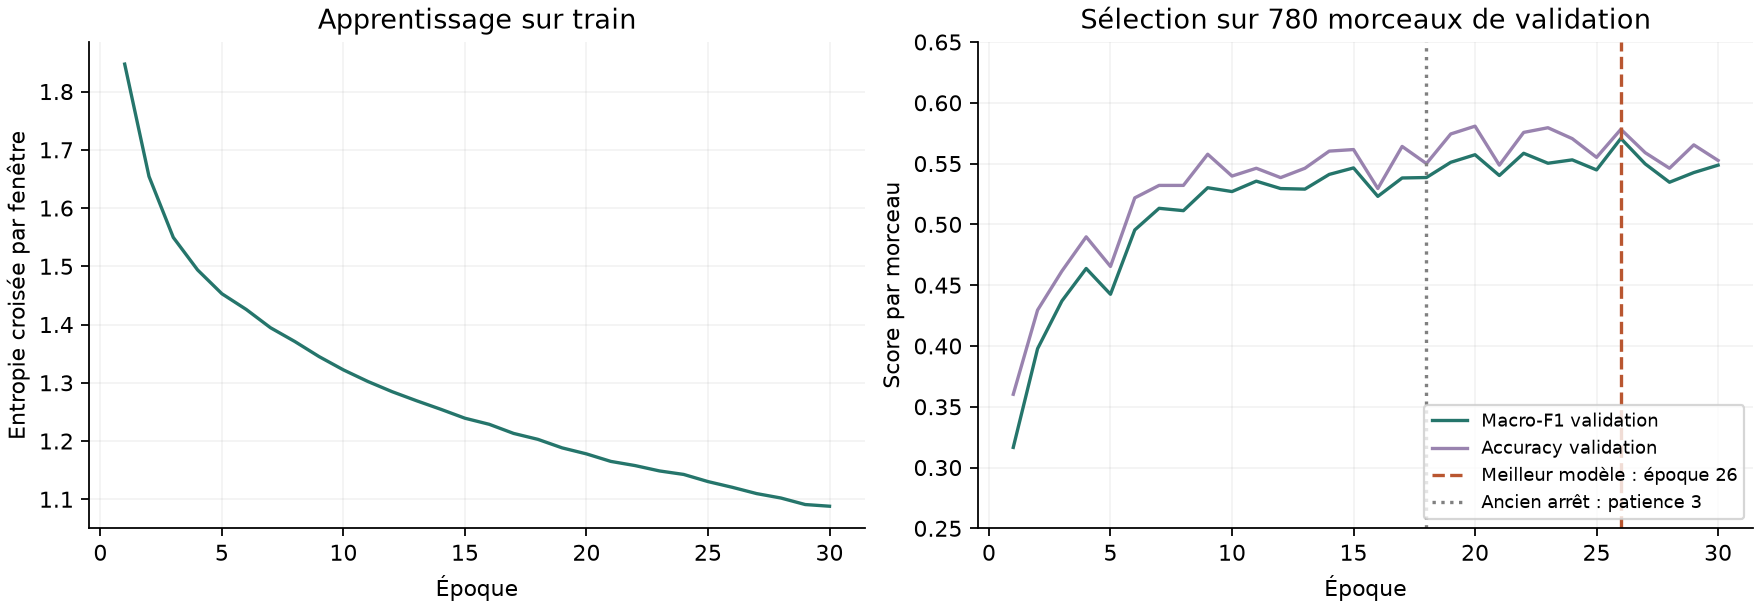

Les poids exportés reproduisent exactement les probabilités validation.
L’inférence a été rejouée sur tous les morceaux train/validation, avec agrégation
et métriques recalculées séparément. **Aucun audio test chargé** ; la V1 reste figée.
Pop demeure faible : 10/94 corrects, F1 0,1370. Aucun entraînement à relancer.

[Résultats détaillés](../reports/SESSION_UTILISATEUR.md) ·
[Preuve de contrôle](../reports/USER_SESSION_CHECK.json) ·
[Conclusion générale](../docs/CONCLUSION_PROJET.md)

Instantané vérifié du run `cnn_user-20261107T073012932719Z` ; empreinte du rapport :
`f748e20f17aaefa3c4717dd70c583ca057d99832823f134e04499a1f3eeef834`.
